# Vorstudie: MSE vs. SPO+ mit linearem Modell (PyEPO, Shortest Path)

**Aufbau** (Code in [prestudy.py](../../src/prestudy.py))
- 5×5-Gitter (40 Kanten), p = 5 Features, PyEPO-Standardgenerator (zufälliges $B$)
- Raster: deg ∈ {1, 2, 4, 6} × noise ∈ {0, 0.5} × n ∈ {100, 1000}
- m = 5 Refits auf disjunkten Trainingsblöcken aus *einem* `genData`-Aufruf je (deg, noise), damit $B$ und die Testmenge ($n_{test}$ = 1000) gleich bleiben
- Modell: `nn.Linear(5, 40)` ohne Regularisierung; Adam, Lernrate 0,01 linear fallend auf 0, 3000 Schritte, Batch 32 – identisch für MSE und SPO+ (Gurobi als Solver)
- PFI: K = 10 Permutationen je Feature; beide Losses eines Refits sehen dieselben Permutationen (gepaarter Vergleich)
- Maße: ΔMSE roh, ΔMSE skalenbereinigt ($a + s\,\hat c$ auf den Trainingsdaten gefittet, entscheidungsneutral), Δ normierter Regret
- Referenz: Orakel $E[c \mid x]$

In [1]:
import numpy as np
import pandas as pd

import prestudy as v

CSV = v.result_path("shortest_path", "pyepo")
if not CSV.exists():
    v.run("shortest_path", "pyepo").to_csv(CSV, index=False)  # ca. 10 min seriell, parallel deutlich weniger
df = pd.read_csv(CSV)
pd.set_option("display.precision", 4)

Welche Features wirken auf wie viele der 40 Kanten? ($B$ ist der erste Zug aus `RandomState(0)` in `genData`.)

In [2]:
B = np.random.RandomState(0).binomial(1, 0.5, (40, 5))
pd.Series(B.sum(0), index=[f"x{j + 1}" for j in range(5)], name="Kanten")

x1    22
x2    19
x3    22
x4    27
x5    16
Name: Kanten, dtype: int64

## 1 Modellgüte auf der Testmenge

Mittelwerte über die 5 Refits. `mse_adj` ist der MSE nach der entscheidungsneutralen Anpassung $a + s\,\hat c$.

In [3]:
(v.performance(df).query("loss != 'oracle'")
 .groupby(["noise", "n", "deg", "loss"])[["mse", "mse_adj", "regret"]].mean()
 .unstack("loss"))

mse             mse_adj          regret            
loss                     mse    spo+         mse    spo+     mse        spo+
noise n      deg                                                            
0.0   100.0  1    1.4911e-12  1.6199  7.6466e-13  0.0402  0.0000  2.5247e-03
             2    4.5775e-03  1.1111  4.5766e-03  0.1240  0.0015  4.2683e-03
             4    1.1950e-01  1.2908  1.1945e-01  0.4865  0.0228  1.4048e-02
             6    9.6863e-01  3.1479  9.6664e-01  1.8749  0.0793  3.5641e-02
      1000.0 1    1.1916e-12  1.7097  5.8043e-13  0.0381  0.0000  3.6652e-05
             2    4.1481e-03  1.1549  4.1500e-03  0.1184  0.0012  4.4017e-04
             4    1.0925e-01  1.2920  1.0924e-01  0.4737  0.0186  4.3050e-03
             6    8.8761e-01  3.3117  8.8736e-01  1.8375  0.0674  1.3822e-02
0.5   100.0  1    1.1876e-01  1.7085  1.1876e-01  0.1526  0.1667  1.7693e-01
             2    8.0112e-02  1.1694  8.0105e-02  0.1951  0.1070  1.2146e-01
             4    2.0959e-01  1.4276  2.0951e-01  0.5623  0.0918  9.1847e-02
             6    1.1748e+00  3.5754  1.1732e+00  2.0407  0.1542  1.0458e-01
      1000.0 1    1.1211e-01  1.6711  1.1211e-01  0.4601  0.1536  1.5497e-01
             2    7.5075e-02  1.1361  7.5075e-02  0.1955  0.0997  1.0023e-01
             4    1.9251e-01  1.3045  1.9250e-01  0.5623  0.0778  6.7527e-02
             6    1.0743e+00  3.0827  1.0740e+00  2.0089  0.1240  6.9034e-02

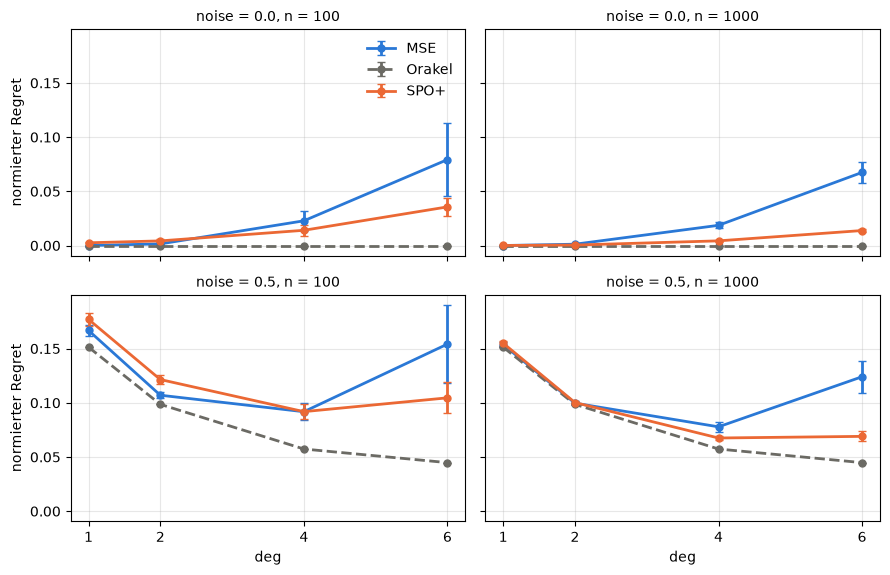

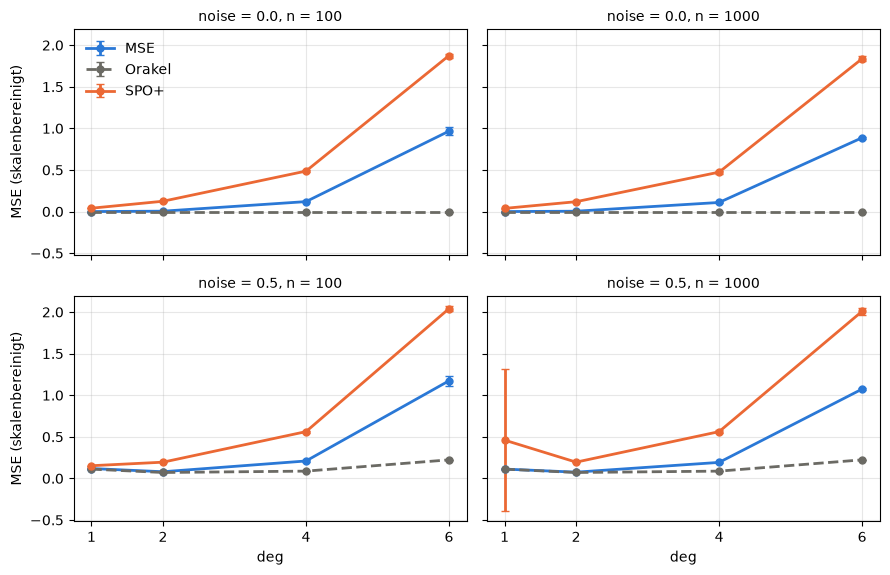

In [4]:
v.plot_over_deg(df, "regret", "normierter Regret")
v.plot_over_deg(df, "mse_adj", "MSE (skalenbereinigt)")

## 2 PFI je Feature

Balken: Mittelwert über die Refits mit 95-%-KI; graue Striche: Orakel. Standard ist n = 1000, noise = 0.5; die Parameter lassen sich ändern.

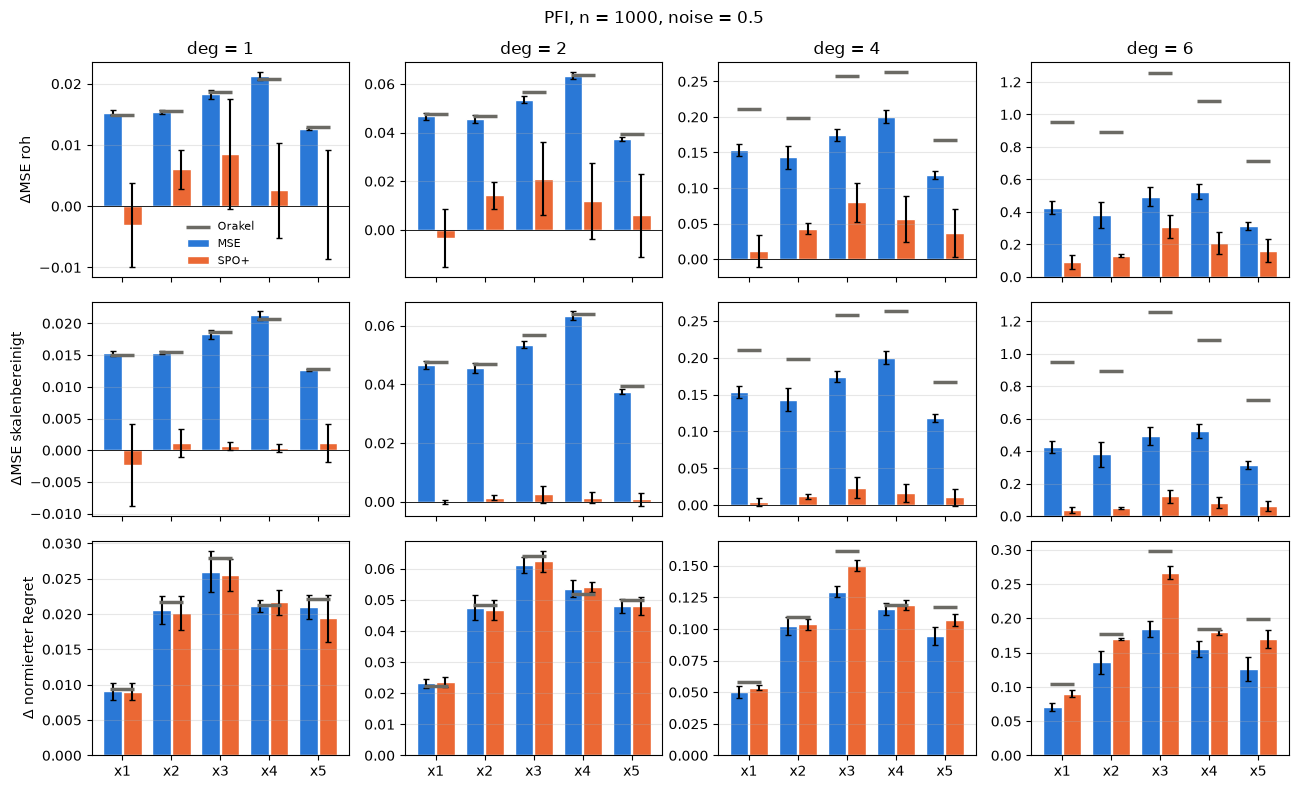

In [5]:
v.plot_pfi(df)

## 3 H1: Rangfolge nach ΔMSE vs. ΔRegret

Kendall's τ zwischen den Rangfolgen der 5 Features nach ΔMSE (skalenbereinigt) und nach ΔRegret, je Modell und Refit berechnet, dann über die Refits gemittelt. Bei 5 Features nimmt τ nur 11 Werte an.

In [6]:
v.kendall_tau(df)

loss               mse  oracle  spo+
noise n      deg                    
0.0   100.0  1    0.36     NaN  0.40
             2    0.44     NaN  0.40
             4    0.32     NaN  0.48
             6    0.28     NaN  0.80
      1000.0 1    0.36     NaN  0.56
             2    0.44     NaN  0.52
             4    0.44     NaN  0.64
             6    0.36     NaN  0.76
      NaN    1     NaN     0.4   NaN
             2     NaN     0.2   NaN
             4     NaN     0.2   NaN
             6     NaN     0.2   NaN
0.5   100.0  1    0.52     NaN  0.28
             2    0.44     NaN  0.28
             4    0.36     NaN  0.48
             6    0.24     NaN  0.64
      1000.0 1    0.28     NaN  0.20
             2    0.28     NaN  0.32
             4    0.40     NaN  0.60
             6    0.32     NaN  0.72
      NaN    1     NaN     0.0   NaN
             2     NaN     0.2   NaN
             4     NaN     0.2   NaN
             6     NaN     0.2   NaN

## 4 Loss-Effekt je Feature: gepaarte Differenz SPO+ − MSE

Je Refit $D_j = \mathrm{PFI}_j(\text{SPO+}) - \mathrm{PFI}_j(\text{MSE})$, Mittelwert und 95-%-t-Intervall über die 5 Refits. `*` = Intervall schließt 0 aus (ohne Holm-Korrektur, nur als Pilot).

In [7]:
v.paired_diff(df).unstack("deg").loc[(0.5, 1000)]

d_mse_adj                                          \
deg                       1                   2                   4   
feature                                                               
x1       -0.0177 ± 0.0067 *  -0.0467 ± 0.0018 *  -0.1493 ± 0.0103 *   
x2       -0.0143 ± 0.0024 *  -0.0441 ± 0.0017 *  -0.1312 ± 0.0142 *   
x3       -0.0176 ± 0.0010 *  -0.0510 ± 0.0018 *  -0.1508 ± 0.0095 *   
x4       -0.0209 ± 0.0010 *  -0.0620 ± 0.0022 *  -0.1835 ± 0.0124 *   
x5       -0.0114 ± 0.0030 *  -0.0368 ± 0.0024 *  -0.1077 ± 0.0131 *   

                                     d_regret                    \
deg                       6                 1                 2   
feature                                                           
x1       -0.3887 ± 0.0397 *  -0.0001 ± 0.0008  +0.0004 ± 0.0017   
x2       -0.3297 ± 0.0706 *  -0.0004 ± 0.0019  -0.0007 ± 0.0025   
x3       -0.3723 ± 0.0383 *  -0.0005 ± 0.0021  +0.0012 ± 0.0018   
x4       -0.4399 ± 0.0386 *  +0.0004 ± 0.0025  +0.0005 ± 0.0013   
x5       -0.2518 ± 0.0378 *  -0.0016 ± 0.0021  -0.0001 ± 0.0025   

                                                 
deg                       4                   6  
feature                                          
x1         +0.0034 ± 0.0042  +0.0201 ± 0.0050 *  
x2         +0.0013 ± 0.0061  +0.0331 ± 0.0178 *  
x3       +0.0205 ± 0.0045 *  +0.0816 ± 0.0087 *  
x4         +0.0035 ± 0.0045  +0.0240 ± 0.0145 *  
x5       +0.0127 ± 0.0065 *  +0.0434 ± 0.0147 *

Alle Einstellungen als Tabelle:

In [8]:
v.paired_diff(df)

d_mse_adj            d_regret
noise n      deg feature                                        
0.0   100.0  1   x1       -0.0156 ± 0.0008 *    -0.0002 ± 0.0012
                 x2       -0.0147 ± 0.0005 *    -0.0012 ± 0.0014
                 x3       -0.0168 ± 0.0010 *    -0.0008 ± 0.0011
                 x4       -0.0206 ± 0.0006 *    -0.0003 ± 0.0011
                 x5       -0.0121 ± 0.0009 *    +0.0002 ± 0.0010
...                                      ...                 ...
0.5   1000.0 6   x1       -0.3887 ± 0.0397 *  +0.0201 ± 0.0050 *
                 x2       -0.3297 ± 0.0706 *  +0.0331 ± 0.0178 *
                 x3       -0.3723 ± 0.0383 *  +0.0816 ± 0.0087 *
                 x4       -0.4399 ± 0.0386 *  +0.0240 ± 0.0145 *
                 x5       -0.2518 ± 0.0378 *  +0.0434 ± 0.0147 *

[80 rows x 2 columns]